# For1Sight V2.7 – Machine Learning Development
## Stage 4: Final Unseen Test – 2026 Season

### Purpose
Evaluate the three saved models on the 2026 events that were held out from training and model selection.

### Strict evaluation rules
- Do not fit or retrain any model in this notebook.
- Do not change model hyperparameters.
- Do not select a different champion based on 2026.
- Load the exact model artifacts saved in Stage 3.
- Exclude the two agreed unmatched 2026 events: Bahrain Grand Prix in Malaysia and United States Grand Prix.
- Evaluate the remaining 16 eligible 2026 events once.

### Models
- Logistic Regression
- Random Forest
- Gradient Boosting (provisional champion selected using 2025 validation)

This notebook creates final test results and charts. It does not write to HDFS or modify Streamlit.

## 0. Project paths and imports

Select the same **Python (For1Sight)** kernel used in the earlier stages.

In [1]:
from pathlib import Path
from datetime import datetime
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

PROJECT_ROOT = Path(r"C:\Users\ayepd\Desktop\For1Sight Project")
DATA_PATH = PROJECT_ROOT / "for1sight_warehouse" / "prediction_training_v2_6.parquet"

STAGE3_OUTPUT_DIR = (
    PROJECT_ROOT / "models" / "race_winner_v2_7"
    / "stage3_validation_20261113_220702"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"V2.6 dataset not found: {DATA_PATH}")
if not STAGE3_OUTPUT_DIR.exists():
    raise FileNotFoundError(
        "Stage 3 model folder not found. Update STAGE3_OUTPUT_DIR to the exact "
        "stage3_validation_TIMESTAMP folder created by your Stage 3 run."
    )

print("Scikit-learn:", sklearn.__version__)
print("Dataset:", DATA_PATH)
print("Stage 3 artifacts:", STAGE3_OUTPUT_DIR)

Scikit-learn: 1.9.0
Dataset: C:\Users\ayepd\Desktop\For1Sight Project\for1sight_warehouse\prediction_training_v2_6.parquet
Stage 3 artifacts: C:\Users\ayepd\Desktop\For1Sight Project\models\race_winner_v2_7\stage3_validation_20261113_220702


## 1. Load Stage 3 manifest and saved models

In [2]:
manifest_path = STAGE3_OUTPUT_DIR / "run_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

print("Project version:", manifest.get("version"))
print("Training season:", manifest.get("training_season"))
print("Validation season:", manifest.get("validation_season"))
print("Final test season:", manifest.get("final_test_season"))
print("Final test used during Stage 3:", manifest.get("final_test_used"))
print("Provisional champion:", manifest.get("provisional_champion"))

if manifest.get("final_test_used") is not False:
    raise ValueError("Stage 3 manifest indicates that the final test was already used.")

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
}

models = {}
for model_name, filename in model_files.items():
    model_path = STAGE3_OUTPUT_DIR / filename
    if not model_path.exists():
        raise FileNotFoundError(f"Saved model not found: {model_path}")
    models[model_name] = joblib.load(model_path)

FEATURE_COLUMNS = manifest["feature_columns"]
print("Loaded models:", list(models))
print("Required model features:", len(FEATURE_COLUMNS))

Project version: V2.7
Training season: 2024
Validation season: 2025
Final test season: 2026
Final test used during Stage 3: False
Provisional champion: Gradient Boosting
Loaded models: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
Required model features: 30


## 2. Load V2.6 data and recreate event eligibility

In [3]:
def normalize_event_name(value):
    value = str(value or "").lower().strip()
    value = re.sub(r"\bgrand\s*prix\b", "", value)
    return re.sub(r"[^a-z0-9]", "", value)

def to_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    return series.astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y"})

df = pd.read_parquet(DATA_PATH, engine="pyarrow")

required = [
    "year", "event_name", "driver_code", "constructor",
    "finishing_position", "is_winner",
    "event_prediction_ready", "model_training_eligible",
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Required columns missing from V2.6 dataset: {missing}")

work = df.copy()
work["year"] = pd.to_numeric(work["year"], errors="coerce").astype("Int64")
work["event_key"] = work["event_name"].map(normalize_event_name)
work["target"] = pd.to_numeric(work["is_winner"], errors="coerce")
work["finishing_position_check"] = pd.to_numeric(work["finishing_position"], errors="coerce")
work["event_prediction_ready_check"] = to_bool(work["event_prediction_ready"])
work["model_training_eligible_check"] = to_bool(work["model_training_eligible"])

excluded_2026_keys = {"bahraininmalaysia", "unitedstates"}
excluded_mask = (work["year"] == 2026) & work["event_key"].isin(excluded_2026_keys)

eligible = work.loc[
    ~excluded_mask
    & work["event_prediction_ready_check"]
    & work["model_training_eligible_check"]
    & work["target"].isin([0, 1])
    & work["finishing_position_check"].notna()
].copy()

eligible["event_id"] = eligible["year"].astype(str) + "_" + eligible["event_key"].astype(str)

test_df = eligible.loc[eligible["year"] == 2026].copy()

print("Original rows:", len(df))
print("Rows excluded under agreed 2026 event rule:", int(excluded_mask.sum()))
print("2026 final test rows:", len(test_df))
print("2026 final test events:", test_df["event_id"].nunique())

display(
    test_df.groupby(["year", "event_name"])
    .agg(driver_rows=("driver_code", "size"), winner_labels=("target", "sum"))
    .reset_index()
)

Original rows: 1354
Rows excluded under agreed 2026 event rule: 44
2026 final test rows: 352
2026 final test events: 16


,year,event_name,driver_rows,winner_labels
0,2026,Australian Grand Prix,22,1
1,2026,Austrian Grand Prix,22,1
2,2026,Azerbaijan Grand Prix,22,1
3,2026,Barcelona Grand Prix,22,1
4,2026,Belgian Grand Prix,22,1
5,2026,British Grand Prix,22,1
6,2026,Canadian Grand Prix,22,1
7,2026,Chinese Grand Prix,22,1
8,2026,Dutch Grand Prix,22,1
9,2026,Hungarian Grand Prix,22,1


## 3. Validate final test events and model feature schema

In [4]:
event_check = (
    test_df.groupby(["event_id", "event_name"])
    .agg(
        driver_rows=("driver_code", "size"),
        distinct_drivers=("driver_code", "nunique"),
        winner_labels=("target", "sum"),
    )
    .reset_index()
)
event_check["valid_event"] = (
    (event_check["driver_rows"] == event_check["distinct_drivers"])
    & (event_check["winner_labels"] == 1)
)
display(event_check.loc[~event_check["valid_event"]])

if test_df.empty:
    raise ValueError("No eligible 2026 test data found.")
if not event_check["valid_event"].all():
    raise ValueError("One or more 2026 events failed the event integrity check.")

missing_features = [c for c in FEATURE_COLUMNS if c not in test_df.columns]
if missing_features:
    raise ValueError(f"Features expected by the saved model are missing: {missing_features}")

print("All 2026 test events passed integrity checks.")
print("Saved-model feature schema is compatible.")

,event_id,event_name,driver_rows,distinct_drivers,winner_labels,valid_event


All 2026 test events passed integrity checks.
Saved-model feature schema is compatible.


## 4. Generate race-level winner probabilities

The saved model estimates a win score for each driver. We convert those scores into probabilities that sum to 1 within each Grand Prix using the same event-level softmax procedure as Stage 3.

These are model-derived relative probabilities, not guaranteed or independently calibrated real-world probabilities.

In [5]:
def event_probability_predictions(model, frame):
    X = frame[FEATURE_COLUMNS].copy()
    raw_p = model.predict_proba(X)[:, 1]

    result = frame[
        ["event_id", "year", "event_name", "driver_code", "target", "starting_grid"]
    ].copy()
    result["raw_win_score"] = raw_p

    eps = 1e-8
    clipped = np.clip(raw_p, eps, 1 - eps)
    result["log_odds_score"] = np.log(clipped / (1 - clipped))

    def softmax_group(values):
        values = np.asarray(values, dtype=float)
        shifted = values - np.max(values)
        exp_values = np.exp(shifted)
        return exp_values / exp_values.sum()

    result["race_win_probability"] = (
        result.groupby("event_id")["log_odds_score"]
        .transform(softmax_group)
    )
    return result

test_predictions = {
    name: event_probability_predictions(model, test_df)
    for name, model in models.items()
}

for name, pred in test_predictions.items():
    probability_sums = pred.groupby("event_id")["race_win_probability"].sum()
    print(
        name,
        "| probability sum range:",
        round(float(probability_sums.min()), 8),
        "to",
        round(float(probability_sums.max()), 8),
    )

Logistic Regression | probability sum range: 1.0 to 1.0
Random Forest | probability sum range: 1.0 to 1.0
Gradient Boosting | probability sum range: 1.0 to 1.0


C:\Users\ayepd\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['driver_circuit_prior_avg_finish' 'constructor_circuit_prior_avg_finish']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\ayepd\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['driver_circuit_prior_avg_finish' 'constructor_circuit_prior_avg_finish']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\ayepd\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features

## 5. Calculate event-level and driver-level metrics

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

def evaluate_event_predictions(pred):
    event_rows = []

    for event_id, group in pred.groupby("event_id"):
        group = group.sort_values(
            "race_win_probability", ascending=False
        ).reset_index(drop=True)

        winner_positions = np.flatnonzero(group["target"].to_numpy() == 1)
        if len(winner_positions) != 1:
            raise ValueError(f"{event_id} does not have exactly one winner.")

        winner_index = int(winner_positions[0])
        winner_probability = float(group.loc[winner_index, "race_win_probability"])

        event_rows.append({
            "event_id": event_id,
            "event_name": group.loc[0, "event_name"],
            "actual_winner": group.loc[winner_index, "driver_code"],
            "predicted_winner": group.loc[0, "driver_code"],
            "top1_correct": winner_index == 0,
            "top3_correct": winner_index < 3,
            "winner_rank": winner_index + 1,
            "winner_probability": winner_probability,
            "winner_log_loss": -np.log(max(winner_probability, 1e-15)),
            "multiclass_brier": float(np.sum(
                (group["race_win_probability"].to_numpy()
                 - group["target"].to_numpy()) ** 2
            )),
            "reciprocal_rank": 1.0 / (winner_index + 1),
        })

    event_metrics = pd.DataFrame(event_rows)

    summary = {
        "Top-1 accuracy (%)": event_metrics["top1_correct"].mean() * 100,
        "Top-3 accuracy (%)": event_metrics["top3_correct"].mean() * 100,
        "Winner log loss (lower better)": event_metrics["winner_log_loss"].mean(),
        "Multiclass Brier (lower better)": event_metrics["multiclass_brier"].mean(),
        "Mean reciprocal rank": event_metrics["reciprocal_rank"].mean(),
        "Driver-row ROC-AUC": roc_auc_score(pred["target"], pred["raw_win_score"]),
        "Driver-row average precision": average_precision_score(
            pred["target"], pred["raw_win_score"]
        ),
        "Events evaluated": len(event_metrics),
    }
    return summary, event_metrics

test_metrics = {}
test_event_details = {}

for name, pred in test_predictions.items():
    summary, details = evaluate_event_predictions(pred)
    test_metrics[name] = summary
    test_event_details[name] = details

metrics_df = pd.DataFrame(test_metrics).T.reset_index(names="Model")
display(metrics_df.round(4))

,Model,Top-1 accuracy (%),Top-3 accuracy (%),Winner log loss (lower better),Multiclass Brier (lower better),Mean reciprocal rank,Driver-row ROC-AUC,Driver-row average precision,Events evaluated
0,Logistic Regression,43.75,75.00,1.3396,0.6202,0.6458,0.9500,0.5813,16.0
1,Random Forest,62.50,93.75,1.2312,0.5957,0.7760,0.9717,0.5725,16.0
2,Gradient Boosting,62.50,87.50,1.1782,0.5407,0.7781,0.9671,0.5885,16.0


## 6. Calculate the 2026 starting-grid P1 baseline

In [7]:
def starting_grid_baseline(frame):
    event_results = []

    for event_id, group in frame.groupby("event_id"):
        valid_grid = group.dropna(subset=["starting_grid"]).copy()
        winner = valid_grid.loc[valid_grid["target"] == 1]

        if valid_grid.empty or len(winner) != 1:
            continue

        winner_grid = float(winner.iloc[0]["starting_grid"])
        pole_grid = float(valid_grid["starting_grid"].min())

        event_results.append({
            "event_id": event_id,
            "event_name": winner.iloc[0]["event_name"],
            "actual_winner": winner.iloc[0]["driver_code"],
            "actual_winner_grid": winner_grid,
            "predicted_winner": valid_grid.loc[
                valid_grid["starting_grid"] == pole_grid, "driver_code"
            ].iloc[0],
            "top1_correct": winner_grid == pole_grid,
            "top3_correct": winner_grid <= 3,
        })

    return pd.DataFrame(event_results)

baseline_details = starting_grid_baseline(test_df)
baseline_summary = {
    "Model": "Starting-grid P1 baseline",
    "Top-1 accuracy (%)": baseline_details["top1_correct"].mean() * 100,
    "Top-3 accuracy (%)": baseline_details["top3_correct"].mean() * 100,
    "Winner log loss (lower better)": np.nan,
    "Multiclass Brier (lower better)": np.nan,
    "Mean reciprocal rank": np.nan,
    "Driver-row ROC-AUC": np.nan,
    "Driver-row average precision": np.nan,
    "Events evaluated": len(baseline_details),
}

comparison_df = pd.concat(
    [metrics_df, pd.DataFrame([baseline_summary])],
    ignore_index=True
)
display(comparison_df.round(4))

,Model,Top-1 accuracy (%),Top-3 accuracy (%),Winner log loss (lower better),Multiclass Brier (lower better),Mean reciprocal rank,Driver-row ROC-AUC,Driver-row average precision,Events evaluated
0,Logistic Regression,43.75,75.00,1.3396,0.6202,0.6458,0.9500,0.5813,16.0
1,Random Forest,62.50,93.75,1.2312,0.5957,0.7760,0.9717,0.5725,16.0
2,Gradient Boosting,62.50,87.50,1.1782,0.5407,0.7781,0.9671,0.5885,16.0
3,Starting-grid P1 baseline,68.75,93.75,NaN,NaN,NaN,NaN,NaN,16.0


## 7. Compare the provisional champion against the baseline

The provisional champion was selected using 2025 validation only. This cell does not change that selection. It reports whether the chosen model generalises to the unseen 2026 season.

In [8]:
provisional_champion = manifest.get("provisional_champion")
if provisional_champion not in test_event_details:
    raise ValueError(f"Champion name not found in loaded models: {provisional_champion}")

champion_2026 = test_event_details[provisional_champion].copy()
baseline_top1 = float(baseline_details["top1_correct"].mean() * 100)
champion_top1 = float(champion_2026["top1_correct"].mean() * 100)

print("Provisional champion:", provisional_champion)
print("2026 champion Top-1 accuracy:", round(champion_top1, 2), "%")
print("2026 P1 baseline Top-1 accuracy:", round(baseline_top1, 2), "%")
print("Difference (model minus baseline):", round(champion_top1 - baseline_top1, 2), "percentage points")

if champion_top1 > baseline_top1:
    print("The provisional champion outperformed the P1 baseline on Top-1 accuracy.")
elif champion_top1 < baseline_top1:
    print("The provisional champion did not outperform the P1 baseline on Top-1 accuracy.")
else:
    print("The provisional champion matched the P1 baseline on Top-1 accuracy.")

Provisional champion: Gradient Boosting
2026 champion Top-1 accuracy: 62.5 %
2026 P1 baseline Top-1 accuracy: 68.75 %
Difference (model minus baseline): -6.25 percentage points
The provisional champion did not outperform the P1 baseline on Top-1 accuracy.


## 8. Inspect race-by-race winner predictions

In [9]:
for name, details in test_event_details.items():
    print("\\n", name)
    display(details.sort_values("event_name"))

print("\\nStarting-grid baseline:")
display(baseline_details.sort_values("event_name"))

\n Logistic Regression


,event_id,event_name,actual_winner,predicted_winner,top1_correct,top3_correct,winner_rank,winner_probability,winner_log_loss,multiclass_brier,reciprocal_rank
0,2026_australian,Australian Grand Prix,RUS,RUS,True,True,1,0.425459,0.854587,0.474980,1.000000
1,2026_austrian,Austrian Grand Prix,RUS,HAM,False,False,4,0.075574,2.582639,1.271499,0.250000
2,2026_azerbaijan,Azerbaijan Grand Prix,RUS,RUS,True,True,1,0.650246,0.430405,0.148568,1.000000
3,2026_barcelona,Barcelona Grand Prix,HAM,ANT,False,True,2,0.280210,1.272215,0.857192,0.500000
4,2026_belgian,Belgian Grand Prix,ANT,RUS,False,False,4,0.068382,2.682639,1.145594,0.250000
5,2026_british,British Grand Prix,LEC,HAM,False,False,6,0.019991,3.912452,1.289693,0.166667
6,2026_canadian,Canadian Grand Prix,ANT,ANT,True,True,1,0.655216,0.422790,0.191820,1.000000
7,2026_chinese,Chinese Grand Prix,ANT,RUS,False,True,2,0.231257,1.464227,0.819326,0.500000
8,2026_dutch,Dutch Grand Prix,NOR,NOR,True,True,1,0.537279,0.621238,0.261742,1.000000
9,2026_hungarian,Hungarian Grand Prix,NOR,LEC,False,True,2,0.290577,1.235887,0.645368,0.500000


\n Random Forest


,event_id,event_name,actual_winner,predicted_winner,top1_correct,top3_correct,winner_rank,winner_probability,winner_log_loss,multiclass_brier,reciprocal_rank
0,2026_australian,Australian Grand Prix,RUS,RUS,True,True,1,0.481483,0.730884,0.313718,1.000000
1,2026_austrian,Austrian Grand Prix,RUS,RUS,True,True,1,0.240436,1.425299,0.689960,1.000000
2,2026_azerbaijan,Azerbaijan Grand Prix,RUS,RUS,True,True,1,0.494018,0.705184,0.300538,1.000000
3,2026_barcelona,Barcelona Grand Prix,HAM,HAM,True,True,1,0.367415,1.001263,0.496860,1.000000
4,2026_belgian,Belgian Grand Prix,ANT,RUS,False,True,3,0.181493,1.706537,0.799602,0.333333
5,2026_british,British Grand Prix,LEC,ANT,False,False,4,0.075182,2.587848,1.101935,0.250000
6,2026_canadian,Canadian Grand Prix,ANT,RUS,False,True,2,0.305239,1.186659,0.671252,0.500000
7,2026_chinese,Chinese Grand Prix,ANT,RUS,False,True,2,0.292686,1.228656,0.627239,0.500000
8,2026_dutch,Dutch Grand Prix,NOR,NOR,True,True,1,0.352915,1.041527,0.505738,1.000000
9,2026_hungarian,Hungarian Grand Prix,NOR,LEC,False,True,2,0.276231,1.286517,0.659039,0.500000


\n Gradient Boosting


,event_id,event_name,actual_winner,predicted_winner,top1_correct,top3_correct,winner_rank,winner_probability,winner_log_loss,multiclass_brier,reciprocal_rank
0,2026_australian,Australian Grand Prix,RUS,RUS,True,True,1,0.848263,0.164564,0.026900,1.00
1,2026_austrian,Austrian Grand Prix,RUS,RUS,True,True,1,0.630869,0.460658,0.189346,1.00
2,2026_azerbaijan,Azerbaijan Grand Prix,RUS,RUS,True,True,1,0.804900,0.217037,0.054245,1.00
3,2026_barcelona,Barcelona Grand Prix,HAM,RUS,False,True,2,0.427984,0.848669,0.551516,0.50
4,2026_belgian,Belgian Grand Prix,ANT,ANT,True,True,1,0.614677,0.486659,0.191111,1.00
5,2026_british,British Grand Prix,LEC,ANT,False,False,4,0.013691,4.291024,1.399707,0.25
6,2026_canadian,Canadian Grand Prix,ANT,RUS,False,True,2,0.088990,2.419228,1.516794,0.50
7,2026_chinese,Chinese Grand Prix,ANT,ANT,True,True,1,0.553780,0.590989,0.322448,1.00
8,2026_dutch,Dutch Grand Prix,NOR,NOR,True,True,1,0.711342,0.340602,0.112564,1.00
9,2026_hungarian,Hungarian Grand Prix,NOR,NOR,True,True,1,0.555995,0.586996,0.288023,1.00


\nStarting-grid baseline:


,event_id,event_name,actual_winner,actual_winner_grid,predicted_winner,top1_correct,top3_correct
0,2026_australian,Australian Grand Prix,RUS,1.0,RUS,True,True
1,2026_austrian,Austrian Grand Prix,RUS,1.0,RUS,True,True
2,2026_azerbaijan,Azerbaijan Grand Prix,RUS,1.0,RUS,True,True
3,2026_barcelona,Barcelona Grand Prix,HAM,2.0,RUS,False,True
4,2026_belgian,Belgian Grand Prix,ANT,1.0,ANT,True,True
5,2026_british,British Grand Prix,LEC,2.0,ANT,False,True
6,2026_canadian,Canadian Grand Prix,ANT,2.0,RUS,False,True
7,2026_chinese,Chinese Grand Prix,ANT,1.0,ANT,True,True
8,2026_dutch,Dutch Grand Prix,NOR,1.0,NOR,True,True
9,2026_hungarian,Hungarian Grand Prix,NOR,1.0,NOR,True,True


## 9. Visualise final test performance

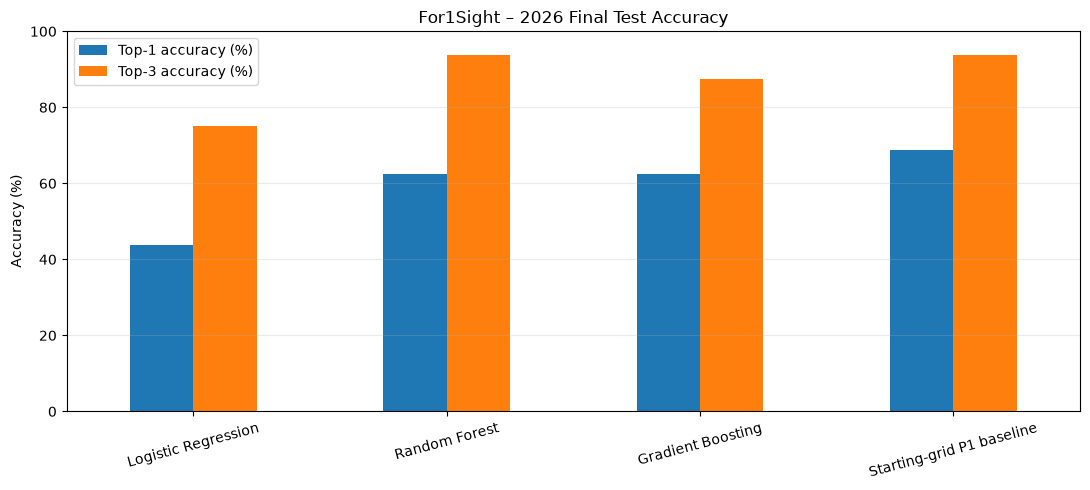

In [10]:
plot_df = comparison_df.set_index("Model")

ax = plot_df[["Top-1 accuracy (%)", "Top-3 accuracy (%)"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 100), rot=15
)
ax.set_title("For1Sight – 2026 Final Test Accuracy")
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

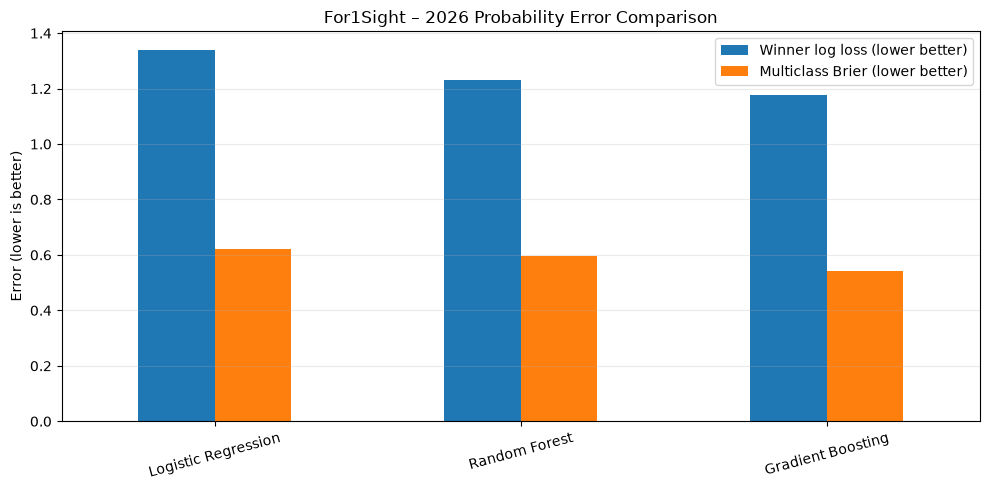

In [11]:
model_only_metrics = metrics_df.set_index("Model")

ax = model_only_metrics[
    ["Winner log loss (lower better)", "Multiclass Brier (lower better)"]
].plot(kind="bar", figsize=(10, 5), rot=15)
ax.set_title("For1Sight – 2026 Probability Error Comparison")
ax.set_ylabel("Error (lower is better)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Save final 2026 test results

In [12]:
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = (
    PROJECT_ROOT / "models" / "race_winner_v2_7"
    / f"stage4_final_test_2026_{run_id}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

comparison_df.to_csv(OUTPUT_DIR / "model_comparison_final_test_2026.csv", index=False)
baseline_details.to_csv(OUTPUT_DIR / "starting_grid_baseline_2026.csv", index=False)

for model_name, details in test_event_details.items():
    safe_name = model_name.lower().replace(" ", "_")
    details.to_csv(OUTPUT_DIR / f"{safe_name}_event_predictions_2026.csv", index=False)

all_predictions = []
for model_name, pred in test_predictions.items():
    temp = pred.copy()
    temp["model"] = model_name
    all_predictions.append(temp)

pd.concat(all_predictions, ignore_index=True).to_csv(
    OUTPUT_DIR / "driver_probabilities_2026.csv", index=False
)

stage4_manifest = {
    "project": "For1Sight",
    "version": "V2.7",
    "stage": "Stage 4 - final unseen test",
    "run_id": run_id,
    "source_stage3_artifacts": str(STAGE3_OUTPUT_DIR),
    "training_season": 2024,
    "validation_season": 2025,
    "final_test_season": 2026,
    "excluded_2026_event_keys": sorted(excluded_2026_keys),
    "events_evaluated": int(test_df["event_id"].nunique()),
    "provisional_champion_from_2025": provisional_champion,
    "models_evaluated": list(models.keys()),
    "models_retrained": False,
    "test_used_for_model_selection": False,
    "scikit_learn_version": sklearn.__version__,
}
(OUTPUT_DIR / "run_manifest.json").write_text(
    json.dumps(stage4_manifest, indent=2), encoding="utf-8"
)

print("Final test outputs saved to:", OUTPUT_DIR)
print("Models retrained: False")
print("2026 used for model selection: False")

Final test outputs saved to: C:\Users\ayepd\Desktop\For1Sight Project\models\race_winner_v2_7\stage4_final_test_2026_20261113_221724
Models retrained: False
2026 used for model selection: False


## 11. Interpretation and limitations

- There are 16 eligible 2026 Grand Prix events. One additional correct race changes Top-1 accuracy by 6.25 percentage points.
- Report event-level Top-1 and Top-3 accuracy as the main race-winner results.
- Use winner log loss and multiclass Brier score to compare the quality of the event-level probability distributions.
- ROC-AUC and average precision are supplementary driver-row metrics, not direct race-winner accuracy.
- RMSE, MAE and R² are regression metrics and are not the primary metrics for this binary / one-winner-per-event classification task.
- The P1 baseline has no probability distribution in this notebook, so its log loss and Brier score are intentionally left blank.
- The model probabilities are generated by event-wise softmax of classifier scores. Do not call them calibrated probabilities unless a separate calibration study supports that claim.
- This is a small test sample and results should be interpreted with caution.

## 12. Stage 4 completion checklist

- [ ] Loaded the exact Stage 3 saved models.
- [ ] Confirmed the 2026 test data contains 16 eligible events.
- [ ] Excluded the two agreed unmatched 2026 events.
- [ ] Did not retrain or tune models.
- [ ] Compared all three models with the P1 baseline.
- [ ] Reviewed event-by-event predictions.
- [ ] Saved final test metrics and prediction outputs.

**Next stage:** Stage 5 – integrate the selected model into the existing Streamlit Prediction Analysis page without changing the Dashboard, Driver Comparison or Circuit Performance pages.